In [325]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [326]:
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [327]:
len(words)

32033

In [328]:
#build vocab of characters
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [329]:
# build the dataset

block_size = 3 # context length: how many characters do we take to predict the next one?
X, Y = [], []
for w in words[:3]:
    
    print(w)
    context = [0] * block_size # start with padded context of just zero tokens
    #print(context)
    for char in w + '.':
        ix = stoi[char]
        X.append(context)
        Y.append(ix)
        #print(ix)
        print(''.join(itos[i] for i in context), '--->', itos[ix])
        context = context[1:] + [ix] # crop context and append
        print(context)
        
X = torch.tensor(X)
Y = torch.tensor(Y)

emma
... ---> e
[0, 0, 5]
..e ---> m
[0, 5, 13]
.em ---> m
[5, 13, 13]
emm ---> a
[13, 13, 1]
mma ---> .
[13, 1, 0]
olivia
... ---> o
[0, 0, 15]
..o ---> l
[0, 15, 12]
.ol ---> i
[15, 12, 9]
oli ---> v
[12, 9, 22]
liv ---> i
[9, 22, 9]
ivi ---> a
[22, 9, 1]
via ---> .
[9, 1, 0]
ava
... ---> a
[0, 0, 1]
..a ---> v
[0, 1, 22]
.av ---> a
[1, 22, 1]
ava ---> .
[22, 1, 0]


In [330]:
# build the dataset
import random

def build_dataset(words):  
    block_size = 3 # context length: how many characters do we take to predict the next one?
    X, Y = [], []
    for w in words:

        #print(w)
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            #print(''.join(itos[i] for i in context), '--->', itos[ix])
            context = context[1:] + [ix] # crop and append

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y


random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [331]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([16, 3]), torch.int64, torch.Size([16]), torch.int64)

In [332]:
C = torch.randn((27, 2))

In [333]:
emb = C[X]
emb.shape

torch.Size([16, 3, 2])

In [49]:
W1 = torch.randn((6, 100))
b1 = torch.randn(100)

In [50]:
emb @ W1 + b1

RuntimeError: mm: mat1 and mat2 shapes cannot be multiplied (96x2 and 6x100)

In [77]:
torch.cat([emb[:, 0, :], emb[:, 1, :], emb[:, 2, :]], 1).shape

torch.Size([32, 6])

In [78]:
torch.cat(torch.unbind(emb, 1), 1).shape

torch.Size([32, 6])

In [79]:
emb.shape

torch.Size([32, 3, 2])

In [81]:
emb.view(32, 6) == torch.cat(torch.unbind(emb, 1), 1)

tensor([[True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, T

In [ ]:
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
h

tensor([[-0.7964, -0.9994, -0.1856,  ..., -0.8946, -0.2379, -0.6048],
        [-0.9178, -0.9993, -0.2648,  ..., -0.4543,  0.1769, -0.3765],
        [-0.9939, -0.9987, -0.2865,  ...,  0.9078,  0.7555,  0.1099],
        ...,
        [-0.7152, -0.8609, -0.9210,  ...,  0.5479, -0.9587, -0.3716],
        [ 0.8911, -0.9999, -0.4078,  ..., -1.0000, -0.9974, -0.9841],
        [ 0.9530, -0.9984, -0.8469,  ..., -0.9196, -0.9964, -0.9326]])

In [89]:
h.shape

torch.Size([32, 100])

In [93]:
W2 = torch.randn((100, 27))
b2 = torch.randn(27)

In [94]:
logits = h @ W2 + b2

In [95]:
logits.shape

torch.Size([32, 27])

In [97]:
counts = logits.exp()

In [98]:
prob = counts / counts.sum(1, keepdim=True)

In [99]:
prob.shape

torch.Size([32, 27])

In [105]:
loss = -prob[torch.arange(32), Y].log().mean()
loss

tensor(17.0832)

In [106]:
#============= writing efficiently now ==============

In [242]:
Xtr.shape, Ytr.shape #dataset

(torch.Size([182625, 3]), torch.Size([182625]))

In [334]:
g = torch.Generator().manual_seed(21)
C = torch.randn((27, 10)).float()
W1 = torch.randn((30, 200))
b1 = torch.randn(200)
W2 = torch.randn((200, 27))
b2 = torch.randn(27)
parameters = [C, W1, b1, W2, b2]

In [335]:
sum(p.nelement() for p in parameters) #number of parameters in total

11897

In [336]:
for p in parameters:
    p.requires_grad = True

In [337]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [338]:
lri =[]
lossi = []
stepi = []

In [314]:
epochs = 100000
for k in range(epochs):

    #minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (32,))

    #forward pass
    emb = C[Xtr[ix]] #[32, 3, 2]
    h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # [32, 100]
    logits = h @ W2 + b2 #[32, 27]
    #counts = logits.exp()
    #prob = counts / counts.sum(1, keepdim=True)
    #loss = -prob[torch.arange(32), Y].log().mean()
    loss = F.cross_entropy(logits, Ytr[ix])
    #print(loss.item())

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    #update
    #lr = lrs[k]
    lr=0.1 if k < epochs/2 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    #track stats
    #lri.append(lre[k])
    stepi.append(k)
    lossi.append(loss.log10().item())

print(loss.item())

2.2909045219421387


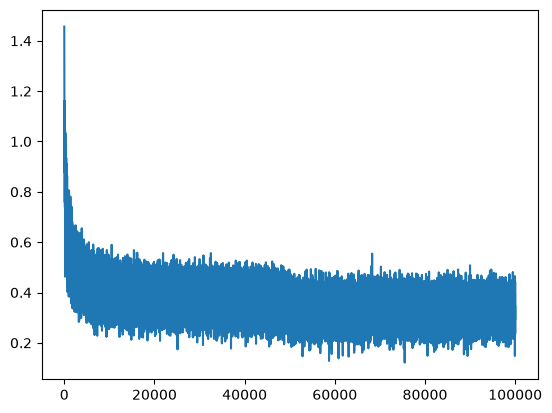

In [309]:
plt.plot(stepi, lossi)

In [310]:
#training split, dev/validation split, test split
# 80, 10, 10 %

In [315]:
emb = C[Xtr] #[32, 3, 2]
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # [32, 100]
logits = h @ W2 + b2 #[32, 27]
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.1174, grad_fn=<NllLossBackward0>)

In [316]:
emb = C[Xdev] #[32, 3, 2]
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # [32, 100]
logits = h @ W2 + b2 #[32, 27]
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.1621, grad_fn=<NllLossBackward0>)

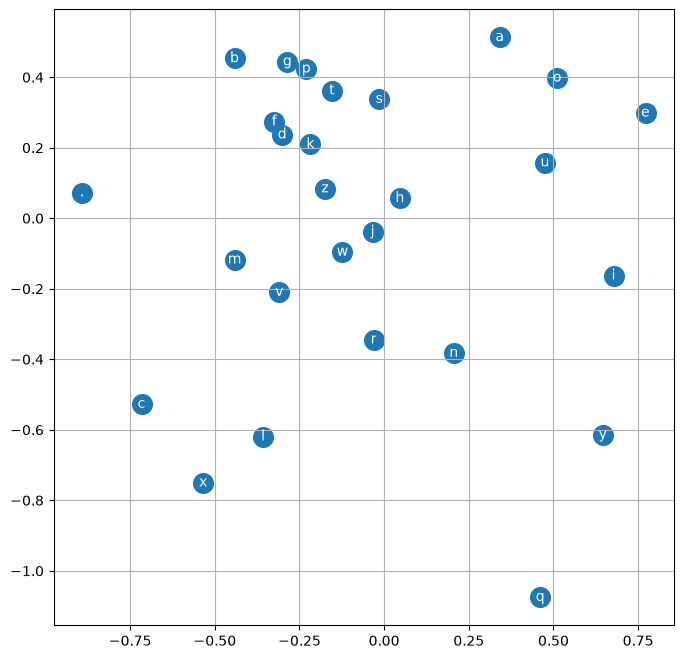

In [274]:
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color="white")    
plt.grid('minor')

In [317]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
        emb = C[torch.tensor([context])] # (1,block_size,d)
        h = torch.tanh(emb.view(1, -1) @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break

    print(''.join(itos[i] for i in out))

carlah.
amelle.
khyrilyn.
taty.
salan.
kena.
hutjaven.
rha.
kaeli.
nellara.
chaihi.
kaleigh.
ham.
pora.
quint.
shoilea.
jadbi.
watell.
dearynix.
kael.
